# Mod 6 Homework Reflections 1–4
**Rupal Paliwal** — all code used for the written answers (submitted separately as a PDF).

Data files are expected in the same folder as this notebook. The loader accepts either naming
style (`homework_4.2.a.csv` or `homework_4_2_a.csv`). Cells that need a dataset that is not present
print a message and skip, so the notebook always runs top to bottom.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats
from sklearn.neighbors import NearestNeighbors
from sklearn.linear_model import LogisticRegression

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
rng = np.random.default_rng(42)

def load(name):
    """Load homework_<a>.<b>[.<c>].csv, trying dotted and underscored names."""
    for cand in (f"{name}.csv", f"{name.replace('.', '_')}.csv"):
        if os.path.exists(cand):
            return pd.read_csv(cand)
    print(f"[skip] {name}.csv not found in {os.getcwd()}")
    return None

## Reflection 1 — Matching (homework_1.2.csv)

### 1.1 Is the farthest match (0.2102) too far?
Diagnostics: scale of the distance, common support, covariate balance after matching, and
sensitivity of the effect to a caliper. A useful feature of this file: **Y = Z + 0.5·X exactly**,
so the true effect is known (0.5) and we can see directly how much bias the far matches add.

In [2]:
hw1 = load("homework_1.2")
if hw1 is None:
    raise SystemExit("Put homework_1.2.csv next to this notebook")

t, c = hw1[hw1.X == 1].copy(), hw1[hw1.X == 0]
print(f"Rows: {len(hw1)}  (treated {len(t)}, control {len(c)})")
print(f"Max |Y - Z - 0.5*X| = {(hw1.Y - hw1.Z - 0.5 * hw1.X).abs().max():.1e}  -> true effect is exactly 0.5")

# Approach (A): nearest control for each treated unit
dist, idx = NearestNeighbors(n_neighbors=1).fit(c[["Z"]]).kneighbors(t[["Z"]])
t["d"] = dist.ravel()
m = c.iloc[idx.ravel()]

# 1) Scale
sd = np.sqrt((t.Z.var() + c.Z.var()) / 2)
print(f"\nFarthest match: {t.d.max():.4f}   median match: {t.d.median():.4f}   pooled SD of Z: {sd:.3f}")
print(f"Farthest match in SD units: {t.d.max() / sd:.2f} SD  (common caliper rule of thumb: 0.2 SD = {0.2*sd:.3f})")
print(f"Treated with match > 0.2 SD: {(t.d > 0.2 * sd).sum()} of {len(t)}")

# 2) Common support
print(f"\nZ range  treated [{t.Z.min():.3f}, {t.Z.max():.3f}]   control [{c.Z.min():.3f}, {c.Z.max():.3f}]")
print(f"Treated above the highest control Z: {(t.Z > c.Z.max()).sum()}")
print(f"Distinct controls used: {m.index.nunique()} of {len(m)} matches")

# 3) Balance
print(f"\nSMD of Z  before: {(t.Z.mean() - c.Z.mean()) / sd:.3f}   after matching: {(t.Z.mean() - m.Z.mean()) / sd:.3f}  (target < 0.1)")

# 4) Sensitivity to a caliper
rows = [{"caliper": "none", "treated kept": len(t), "effect": t.Y.mean() - m.Y.mean()}]
for cal in (0.2, 0.1, 0.05, 0.02):
    k = t.d.values <= cal
    rows.append({"caliper": cal, "treated kept": int(k.sum()),
                 "effect": t.Y.values[k].mean() - m.Y.values[k].mean()})
cal_tab = pd.DataFrame(rows); cal_tab["bias vs 0.5"] = cal_tab.effect - 0.5
print("\n" + cal_tab.round(4).to_string(index=False))

Rows: 100  (treated 48, control 52)
Max |Y - Z - 0.5*X| = 4.9e-10  -> true effect is exactly 0.5

Farthest match: 0.2102   median match: 0.0133   pooled SD of Z: 0.251
Farthest match in SD units: 0.84 SD  (common caliper rule of thumb: 0.2 SD = 0.050)
Treated with match > 0.2 SD: 14 of 48

Z range  treated [0.120, 0.988]   control [0.005, 0.778]
Treated above the highest control Z: 18
Distinct controls used: 20 of 48 matches

SMD of Z  before: 1.170   after matching: 0.173  (target < 0.1)

caliper  treated kept  effect  bias vs 0.5
   none            48  0.5434       0.0434
    0.2            46  0.5363       0.0363
    0.1            38  0.5090       0.0090
   0.05            34  0.5026       0.0026
   0.02            27  0.4997      -0.0003


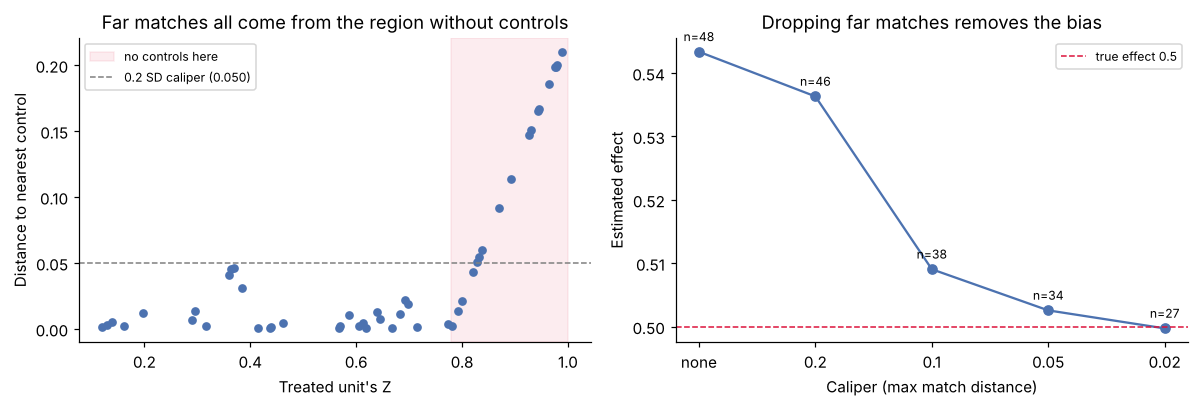

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].axvspan(c.Z.max(), 1.0, color="crimson", alpha=0.08, label="no controls here")
ax[0].scatter(t.Z, t.d, color="#4C72B0", s=22)
ax[0].axhline(0.2 * sd, color="grey", ls="--", lw=1, label=f"0.2 SD caliper ({0.2*sd:.3f})")
ax[0].set_xlabel("Treated unit's Z"); ax[0].set_ylabel("Distance to nearest control")
ax[0].set_title("Far matches all come from the region without controls"); ax[0].legend(fontsize=8)

ct = cal_tab.copy(); ct["label"] = ct.caliper.astype(str)
ax[1].plot(ct.label, ct.effect, "o-", color="#4C72B0")
for _, r in ct.iterrows():
    ax[1].annotate(f"n={r['treated kept']}", (r.label, r.effect), textcoords="offset points", xytext=(0, 7),
                   ha="center", fontsize=8)
ax[1].axhline(0.5, color="crimson", ls="--", lw=1, label="true effect 0.5")
ax[1].set_xlabel("Caliper (max match distance)"); ax[1].set_ylabel("Estimated effect")
ax[1].set_title("Dropping far matches removes the bias"); ax[1].legend(fontsize=8)
fig.tight_layout(); fig.savefig("fig_match.png", dpi=200); plt.show()

### 1.2 A different matching rule: k-nearest neighbours with a caliper and inverse-distance weights
For each treated unit: take its **k** nearest controls, **discard** any farther than a caliper, and
average the kept controls' Y using weights **1/(distance + ε)**. Treated units with no control inside the
caliper are dropped and counted. Compared with the quiz approaches (A: 1 nearest, B: all within 0.2).

In [4]:
def knn_caliper_ipw(df, treat="X", outcome="Y", k=5, caliper=0.2, eps=1e-3):
    zcols = [col for col in df.columns if col.upper().startswith("Z")]
    tt, cc = df[df[treat] == 1], df[df[treat] == 0]
    d, idx = NearestNeighbors(n_neighbors=k).fit(cc[zcols].values).kneighbors(tt[zcols].values)
    yc = cc[outcome].values[idx]                     # (n_treated, k) control outcomes
    w = np.where(d <= caliper, 1 / (d + eps), 0.0)  # zero weight outside the caliper
    has = w.sum(1) > 0
    cf = (w[has] * yc[has]).sum(1) / w[has].sum(1)   # weighted counterfactual per treated unit
    return (tt[outcome].values[has] - cf).mean(), int((~has).sum())

# Quiz approach (B) for reference: all controls within 0.2, mean Y per group
nn = NearestNeighbors(radius=0.2).fit(c[["Z"]])
_, groups = nn.radius_neighbors(t[["Z"]])
cf_b = np.array([c.Y.values[g].mean() for g in groups if len(g)])
eff_b = (t.Y.values[[len(g) > 0 for g in groups]] - cf_b).mean()

n_unmatched = int(sum(len(g) == 0 for g in groups))
rows = [{"method": "A: 1 nearest, no caliper", "effect": t.Y.mean() - m.Y.mean(), "treated dropped": 0},
        {"method": "B as in quiz (all treated Y kept)", "effect": t.Y.mean() - cf_b.mean(), "treated dropped": 0},
        {"method": "B, unmatched treated dropped", "effect": eff_b, "treated dropped": n_unmatched}]
for k, cal in [(5, 0.2), (5, 0.05), (3, 0.05), (10, 0.05)]:
    e, dropped = knn_caliper_ipw(hw1, k=k, caliper=cal)
    rows.append({"method": f"Mine: k={k}, caliper {cal}, 1/d weights", "effect": e, "treated dropped": dropped})
cmp1 = pd.DataFrame(rows); cmp1["bias vs 0.5"] = cmp1.effect - 0.5
print(cmp1.round(4).to_string(index=False))

                               method  effect  treated dropped  bias vs 0.5
             A: 1 nearest, no caliper  0.5434                0       0.0434
    B as in quiz (all treated Y kept)  0.5844                0       0.0844
         B, unmatched treated dropped  0.5689                2       0.0689
  Mine: k=5, caliper 0.2, 1/d weights  0.5449                2       0.0449
 Mine: k=5, caliper 0.05, 1/d weights  0.5040               14       0.0040
 Mine: k=3, caliper 0.05, 1/d weights  0.5036               14       0.0036
Mine: k=10, caliper 0.05, 1/d weights  0.5049               14       0.0049


## Reflection 2

### 2.1 Fixed-effects example (simulated to match the written scenario)
Schools differ in fixed, unobserved ways (neighbourhood, leadership). The question is how much an
extra day of attendance raises a student's score. Pooled OLS is biased because high-attendance
schools are also high-scoring schools. School fixed effects remove that.

In [5]:
r21 = np.random.default_rng(21)
n_sch, n_per = 40, 60
school = np.repeat(np.arange(n_sch), n_per)
school_quality = r21.normal(0, 8, n_sch)[school]                 # unobserved, fixed per school
days = 150 + 1.5 * school_quality + r21.normal(0, 10, school.size) # better schools -> more attendance
score = 200 + 0.30 * days + school_quality + r21.normal(0, 5, school.size)
fe = pd.DataFrame({"school": school, "days": days, "score": score})

pooled = smf.ols("score ~ days", fe).fit()
fixed  = smf.ols("score ~ days + C(school)", fe).fit()
print(f"True effect of one day     : 0.300")
print(f"Pooled OLS coefficient     : {pooled.params['days']:.3f}")
print(f"School fixed-effects coeff : {fixed.params['days']:.3f}  (SE {fixed.bse['days']:.3f})")

True effect of one day     : 0.300
Pooled OLS coefficient     : 0.709
School fixed-effects coeff : 0.308  (SE 0.011)


### 2.2 Bootstrap variance of the mean of a Pareto distribution
Procedure: (1) draw one "full sample" of size N from Pareto(shape a, minimum 1); (2) resample it with
replacement B = 1,000 times, each resample also of size N; (3) compute the mean of each resample;
(4) take the variance of those 1,000 means. Because one heavy-tailed sample can be unrepresentative,
I repeat steps 1–4 for 20 independent full samples per N and report the median and the max/min spread.

NumPy's `rng.pareto(a)` draws a Lomax (Pareto II) variable, so I add 1 to get the classic Pareto
with minimum 1. Its true mean is a/(a−1) and its variance is finite only when a > 2.

 shape a     N  median var of mean  theory sigma^2/N  N * median var  max/min over 20 samples
       3   100            0.004377            0.0075          0.4377                    21.81
       3   300            0.001778            0.0025          0.5334                    5.249
       3  1000           0.0006081           0.00075          0.6081                    1.924
       3  3000           0.0002148           0.00025          0.6445                    2.358
       3 10000           7.416e-05           7.5e-05          0.7416                    6.208
       3 30000           2.259e-05           2.5e-05          0.6776                    1.695
     1.5   100              0.1613               NaN           16.13                      334
     1.5   300               0.162               NaN           48.59                    411.5
     1.5  1000              0.0345               NaN            34.5                    35.35
     1.5  3000             0.01628               NaN        

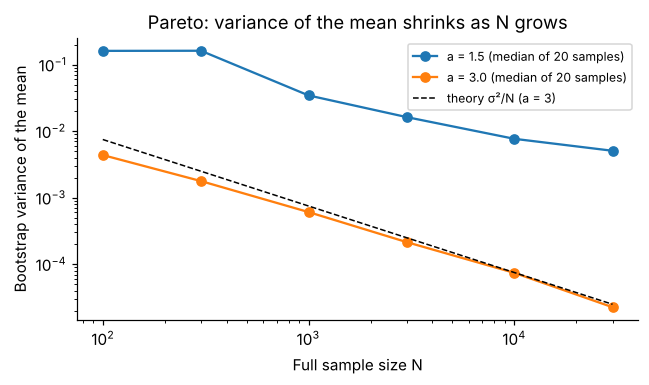

In [6]:
r22 = np.random.default_rng(22)

def bootstrap_var_of_mean(full_sample, B=1000, rng=r22):
    # resample WITH replacement, same size as the full sample; variance of the B resample means
    n = full_sample.size
    means = np.array([full_sample[rng.integers(0, n, n)].mean() for _ in range(B)])
    return means.var(ddof=1)

def pareto(a, n, rng=r22):
    return rng.pareto(a, n) + 1        # numpy draws Lomax; +1 gives classic Pareto with x_min = 1

Ns, R = [100, 300, 1_000, 3_000, 10_000, 30_000], 20   # R independent full samples per N
rows = []
for a in (3.0, 1.5):
    for N in Ns:
        v = np.array([bootstrap_var_of_mean(pareto(a, N)) for _ in range(R)])
        rows.append({"shape a": a, "N": N, "median var of mean": np.median(v),
                     "theory sigma^2/N": (a / ((a - 1) ** 2 * (a - 2))) / N if a > 2 else np.nan,
                     "N * median var": N * np.median(v), "max/min over 20 samples": v.max() / v.min()})
res2 = pd.DataFrame(rows)
print(res2.to_string(index=False, float_format=lambda x: f"{x:.4g}"))

fig, ax = plt.subplots(figsize=(6, 3.6))
for a_, g in res2.groupby("shape a"):
    ax.loglog(g["N"], g["median var of mean"], "o-", label=f"a = {a_} (median of 20 samples)")
th = res2[res2["shape a"] == 3.0]
ax.loglog(th["N"], th["theory sigma^2/N"], "k--", lw=1, label="theory σ²/N (a = 3)")
ax.set_xlabel("Full sample size N"); ax.set_ylabel("Bootstrap variance of the mean")
ax.set_title("Pareto: variance of the mean shrinks as N grows"); ax.legend(fontsize=8); fig.tight_layout(); plt.show()

## Reflection 3

### 3.1 Testing for a change in the second derivative at the event (t = 50)
Centre time at the event, s = t − 50, and let D = 1 after the event. Fit a piecewise quadratic:

value = b0 + b1·s + b2·s² + b3·D + b4·D·s + b5·D·s²

b3 = jump in level, b4 = jump in slope, **b5 = jump in curvature** (second derivative changes by 2·b5).
Test b5 with its t-statistic, and confirm with an F-test of the model with versus without the D·s² term.

In [7]:
def curvature_test(df, ycol, tcol="time", event=50):
    d = df.copy()
    d["s"] = d[tcol] - event
    d["D"] = (d[tcol] >= event).astype(int)
    full = smf.ols(f"{ycol} ~ s + I(s**2) + D + D:s + D:I(s**2)", d).fit()
    restricted = smf.ols(f"{ycol} ~ s + I(s**2) + D + D:s", d).fit()
    f, p, _ = full.compare_f_test(restricted)
    b = full.params["D:I(s ** 2)"]
    print(f"{ycol}: jump in level b3={full.params['D']:.3f} (p={full.pvalues['D']:.3g}), "
          f"slope b4={full.params['D:s']:.4f} (p={full.pvalues['D:s']:.3g}), "
          f"curvature b5={b:.5f} (t={full.tvalues['D:I(s ** 2)']:.2f}, p={full.pvalues['D:I(s ** 2)']:.3g}); "
          f"F-test p={p:.3g}")
    return full

# Simulated series: value_A has a curvature change at 50, value_B does not
r3 = np.random.default_rng(2026)
t = np.arange(0, 101, dtype=float)
s = t - 50
sim3 = pd.DataFrame({
    "time": t,
    "value_A": 5 + 0.10 * s + 0.002 * s**2 + np.where(s >= 0, 0.006 * s**2, 0) + r3.normal(0, 0.4, t.size),
    "value_B": 5 + 0.10 * s + 0.002 * s**2 + r3.normal(0, 0.4, t.size),
})
for col in ("value_A", "value_B"):
    curvature_test(sim3, col)

# Calibration: on 400 series with NO change at 50, how often is b5 'significant' at 5%?
D_ = (s >= 0).astype(int); hits = 0
for seed in range(400):
    yy = 5 + 0.10 * s + 0.002 * s**2 + np.random.default_rng(seed).normal(0, 0.4, s.size)
    mm = smf.ols("y ~ s + I(s**2) + D + D:s + D:I(s**2)", pd.DataFrame({"y": yy, "s": s, "D": D_})).fit()
    hits += mm.pvalues["D:I(s ** 2)"] < 0.05
print(f"False-positive rate of the curvature test under no change: {hits/400:.1%} (should be ~5%)")

hw3 = load("homework_3.1")
if hw3 is not None:
    tcol = [c for c in hw3.columns if "time" in c.lower()][0]
    for col in [c for c in hw3.columns if c.lower().startswith("value")]:
        curvature_test(hw3, col, tcol=tcol)

value_A: jump in level b3=-0.516 (p=0.0325), slope b4=-0.0337 (p=0.125), curvature b5=0.00542 (t=13.00, p=8.38e-23); F-test p=8.38e-23
value_B: jump in level b3=-0.119 (p=0.669), slope b4=0.0181 (p=0.477), curvature b5=-0.00049 (t=-1.01, p=0.314); F-test p=0.314


False-positive rate of the curvature test under no change: 5.8% (should be ~5%)
[skip] homework_3.1.csv not found in /home/claude/hw


### 3.2 Difference-in-differences scenario: breakfast program and attendance
30 schools are tracked for 6 school years. 15 schools start a universal free breakfast program in
year 4; 15 do not. Outcome: school-level average daily attendance rate (%). Both groups share a
gently declining trend; the program schools start ~2 points lower. True program effect = +1.5 points.

Group means:
 post         0      1
treated              
0        89.93  88.74
1        88.13  88.44

DiD by hand: 1.498
Two-way FE DiD: 1.498  SE 0.187  95% CI [1.13, 1.86]  p=1.1e-15
Pre-period slope difference: -0.069 (p=0.59)  -> no evidence against parallel trends


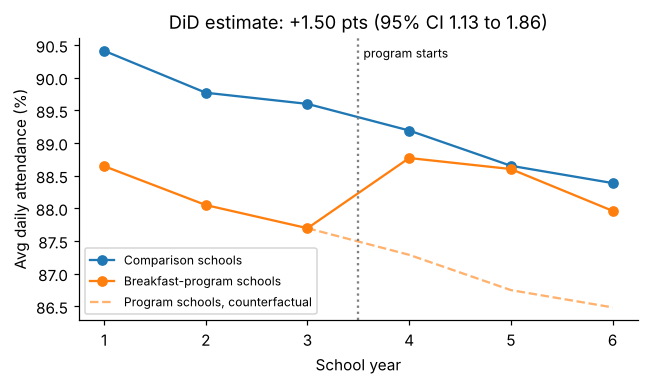

In [8]:
r32 = np.random.default_rng(11)
n_s, years = 30, np.arange(1, 7)
rows = []
for sid in range(n_s):
    treated = int(sid < 15)
    base = 91 - 2.0 * treated + r32.normal(0, 1.0)            # level difference is allowed
    for y in years:
        post = int(y >= 4)
        att = base - 0.4 * y + 1.5 * treated * post + r32.normal(0, 0.6)  # common trend -0.4/yr
        rows.append({"school": sid, "year": y, "treated": treated, "post": post, "attendance": att})
did = pd.DataFrame(rows)

# Basic 2x2 DiD by hand
g = did.groupby(["treated", "post"])["attendance"].mean().unstack()
by_hand = (g.loc[1, 1] - g.loc[1, 0]) - (g.loc[0, 1] - g.loc[0, 0])
print("Group means:\n", g.round(2))
print(f"\nDiD by hand: {by_hand:.3f}")

# Regression DiD with school and year fixed effects, SEs clustered by school
m = smf.ols("attendance ~ treated:post + C(school) + C(year)", did).fit(
    cov_type="cluster", cov_kwds={"groups": did["school"]})
est, se = m.params["treated:post"], m.bse["treated:post"]
print(f"Two-way FE DiD: {est:.3f}  SE {se:.3f}  95% CI [{est-1.96*se:.2f}, {est+1.96*se:.2f}]  p={m.pvalues['treated:post']:.2g}")

# Pre-trend check: years 1-3 only, does the treated group trend differently?
pre = smf.ols("attendance ~ year * treated", did[did.year <= 3]).fit(
    cov_type="cluster", cov_kwds={"groups": did[did.year <= 3]["school"]})
pt = pre.pvalues['year:treated']
print(f"Pre-period slope difference: {pre.params['year:treated']:.3f} (p={pt:.2f})  -> "
      + ("no evidence against parallel trends" if pt > 0.10 else "pre-trends differ: interpret DiD with caution"))

fig, ax = plt.subplots(figsize=(6, 3.6))
tr = did.groupby(["year", "treated"])["attendance"].mean().unstack()
ax.plot(tr.index, tr[0], "o-", label="Comparison schools")
ax.plot(tr.index, tr[1], "o-", label="Breakfast-program schools")
cf = tr[1].iloc[:3].tolist() + [tr[1].iloc[2] + (tr[0].iloc[i] - tr[0].iloc[2]) for i in range(3, 6)]
ax.plot(tr.index[2:], cf[2:], "--", color="C1", alpha=0.6, label="Program schools, counterfactual")
ax.axvline(3.5, color="grey", ls=":"); ax.text(3.55, ax.get_ylim()[1] - 0.3, "program starts", fontsize=8)
ax.set_xlabel("School year"); ax.set_ylabel("Avg daily attendance (%)")
ax.set_title(f"DiD estimate: +{est:.2f} pts (95% CI {est-1.96*se:.2f} to {est+1.96*se:.2f})")
ax.legend(fontsize=8); fig.tight_layout(); fig.savefig("fig_did.png", dpi=200); plt.show()

## Reflection 4

### 4.1 Instrumental variable, method 2: stratify on W
Z is the instrument, X the treatment, Y the outcome, W a covariate. Within each range of W:
effect = (mean Y | Z=1 − mean Y | Z=0) / (mean X | Z=1 − mean X | Z=0). Then average across ranges.

In [9]:
iv = load("homework_4.1")
g = iv.groupby("Z")[["X", "Y"]].mean()
wald = (g.loc[1, "Y"] - g.loc[0, "Y"]) / (g.loc[1, "X"] - g.loc[0, "X"])
print(f"Method 1 (overall Wald ratio): {wald:.4f}")

def stratified_wald(df, n_bins=20, binning="quantile", min_n=10):
    d = df.copy()
    d["bin"] = pd.qcut(d.W, n_bins) if binning == "quantile" else pd.cut(d.W, n_bins)
    out = []
    for b, s in d.groupby("bin", observed=True):
        n0, n1 = (s.Z == 0).sum(), (s.Z == 1).sum()
        if min(n0, n1) < min_n:          # need both Z groups, with enough rows, in the bin
            continue
        m = s.groupby("Z")[["X", "Y"]].mean()
        dx = m.loc[1, "X"] - m.loc[0, "X"]
        out.append({"bin": b, "n": len(s), "dY": m.loc[1, "Y"] - m.loc[0, "Y"], "dX": dx,
                    "ratio": (m.loc[1, "Y"] - m.loc[0, "Y"]) / dx})
    r = pd.DataFrame(out)
    return r, r.ratio.mean(), np.average(r.ratio, weights=r.n), len(r)

r20, simple, weighted, kept = stratified_wald(iv, 20)
print(f"Method 2 (20 quantile bins of W): simple mean {simple:.4f}, size-weighted {weighted:.4f}")
print(r20.round(3).to_string(index=False))

Method 1 (overall Wald ratio): 1.5619
Method 2 (20 quantile bins of W): simple mean 1.5055, size-weighted 1.5055
              bin   n    dY    dX  ratio
 (-3.304, -1.584] 250 1.632 0.967  1.688
 (-1.584, -1.277] 250 1.515 1.122  1.350
 (-1.277, -1.042] 250 1.388 1.056  1.314
 (-1.042, -0.855] 250 1.179 0.915  1.289
 (-0.855, -0.698] 250 1.618 0.994  1.628
 (-0.698, -0.547] 250 1.541 0.966  1.595
 (-0.547, -0.401] 250 1.559 0.928  1.680
 (-0.401, -0.277] 250 1.294 0.834  1.552
 (-0.277, -0.149] 250 1.308 0.941  1.389
(-0.149, -0.0322] 250 1.583 1.055  1.500
 (-0.0322, 0.106] 250 1.483 1.017  1.458
   (0.106, 0.226] 250 1.824 1.135  1.607
   (0.226, 0.358] 250 2.053 1.324  1.551
   (0.358, 0.491] 250 1.924 1.149  1.674
   (0.491, 0.648] 250 1.649 1.048  1.574
   (0.648, 0.814] 250 1.234 0.898  1.374
    (0.814, 1.01] 250 1.413 1.038  1.361
    (1.01, 1.303] 250 1.759 1.046  1.681
   (1.303, 1.685] 250 1.396 0.942  1.482
   (1.685, 4.783] 250 1.357 0.996  1.363


In [10]:
# Sensitivity to the number and type of bins (the main 'issue' discussed in the PDF)
rows = []
for binning in ("quantile", "equal-width"):
    for k in (5, 10, 20, 50, 100, 250):
        r, s_, w_, kept = stratified_wald(iv, k, binning, min_n=1)
        rows.append({"binning": binning, "bins": k, "bins used": kept, "simple mean": s_,
                     "weighted mean": w_, "median": r.ratio.median(),
                     "min ratio": r.ratio.min(), "max ratio": r.ratio.max(),
                     "min |dX|": r.dX.abs().min()})
sens = pd.DataFrame(rows)
print(sens.round(3).to_string(index=False))

    binning  bins  bins used  simple mean  weighted mean  median  min ratio  max ratio  min |dX|
   quantile     5          5        1.516          1.516   1.495      1.446      1.631     0.931
   quantile    10         10        1.509          1.509   1.532      1.315      1.618     0.881
   quantile    20         20        1.506          1.506   1.525      1.289      1.688     0.834
   quantile    50         50        1.510          1.510   1.543      1.027      1.869     0.666
   quantile   100        100        1.515          1.515   1.556      0.435      2.248     0.287
   quantile   250        250        1.077          1.077   1.522   -114.414      8.171     0.005
equal-width     5          5        0.816          1.518   1.495     -1.927      1.616     0.163
equal-width    10          9        0.909          1.514   1.508     -3.689      1.839     0.135
equal-width    20         17        1.617          1.517   1.501     -0.290      4.814     0.242
equal-width    50         42  

Mean W by Z: {0: -0.035, 1: 0.015}
corr(Z, W) = 0.0246


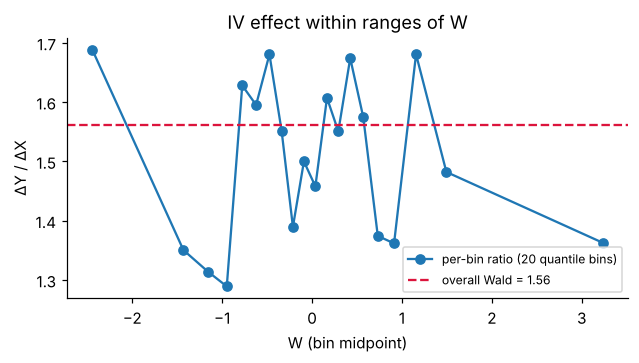

In [11]:
# Why W isn't needed: Z is (close to) independent of W, so W is balanced across Z.
print("Mean W by Z:", iv.groupby("Z").W.mean().round(3).to_dict())
print("corr(Z, W) =", round(iv.Z.corr(iv.W), 4))

fig, ax = plt.subplots(figsize=(6, 3.4))
r, *_ = stratified_wald(iv, 20)
mid = [b.mid for b in r.bin]
ax.plot(mid, r.ratio, "o-", label="per-bin ratio (20 quantile bins)")
ax.axhline(wald, color="crimson", ls="--", label=f"overall Wald = {wald:.2f}")
ax.set_xlabel("W (bin midpoint)"); ax.set_ylabel("ΔY / ΔX"); ax.legend(fontsize=8)
ax.set_title("IV effect within ranges of W"); fig.tight_layout(); plt.show()

### 4.2 College outcome vs test score around the cutoff (75–85)
Raw Y is 0/1, so instead of plotting raw points I plot the **share admitted in 0.5-point bins with 95%
binomial confidence intervals**, marker size ∝ students per bin, plus a light rug of jittered raw
points. Two logistic regressions are overlaid: a **naive** one on X only (smooth, cannot jump), and a
**regression-discontinuity** logistic with a cutoff dummy and separate slopes on each side.

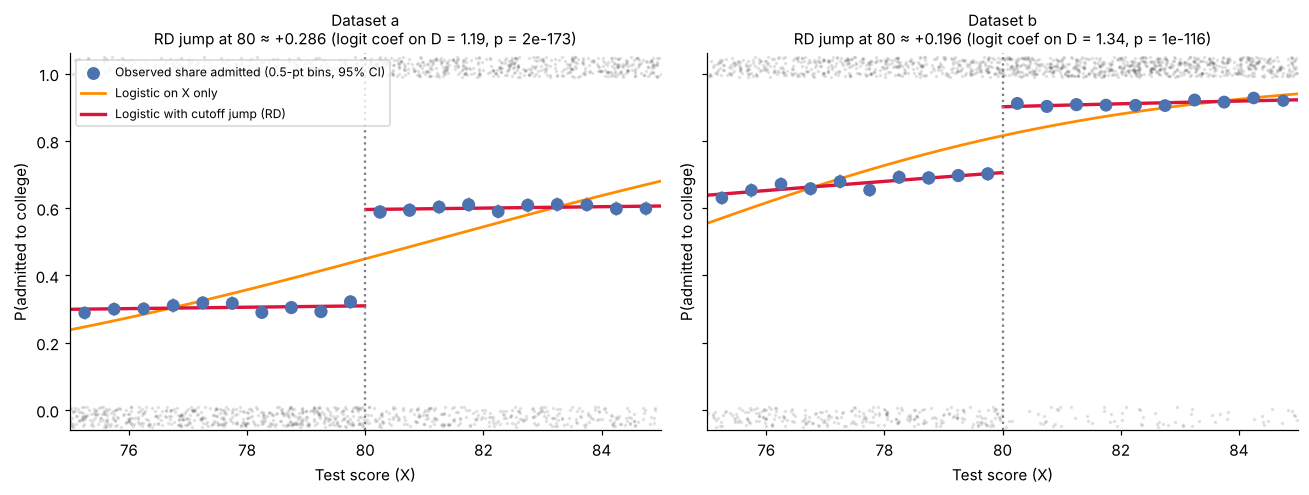

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.8011      0.031    -25.882      0.000      -0.862      -0.740
xc             0.0098      0.011      0.893      0.372      -0.012       0.031
D              1.1906      0.042     28.076      0.000       1.107       1.274
D:xc          -0.0011      0.015     -0.074      0.941      -0.030       0.028
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      0.8751      0.031     28.515      0.000       0.815       0.935
xc             0.0612      0.011      5.740      0.000       0.040       0.082
D              1.3402      0.058     22.964      0.000       1.226       1.455
D:xc          -0.0095      0.021     -0.455      0.649      -0.050       0.031


In [12]:
def rd_plot(df, xcol, ycol, ax, title, lo=75, hi=85, cut=80, width=0.5):
    d = df[(df[xcol] >= lo) & (df[xcol] <= hi)].copy()
    d["xc"] = d[xcol] - cut
    d["D"] = (d[xcol] >= cut).astype(int)

    # binned means + Wilson-style normal CI
    d["bin"] = np.floor(d[xcol] / width) * width + width / 2
    b = d.groupby("bin")[ycol].agg(["mean", "count"]).reset_index()
    se = np.sqrt(b["mean"] * (1 - b["mean"]) / b["count"])
    ax.errorbar(b["bin"], b["mean"], yerr=1.96 * se, fmt="none", ecolor="grey", alpha=0.6, lw=1)
    ax.scatter(b["bin"], b["mean"], s=b["count"] / b["count"].max() * 60, color="#4C72B0",
               zorder=3, label="Observed share admitted (0.5-pt bins, 95% CI)")

    # rug of raw outcomes (jittered) so the 0/1 data is visible but unobtrusive
    sub = d.sample(min(1500, len(d)), random_state=0)
    ax.scatter(sub[xcol], sub[ycol] + rng.uniform(-0.03, 0.03, len(sub)) * 1 + np.where(sub[ycol] == 1, 0.02, -0.02),
               s=2, alpha=0.08, color="black")

    grid = np.linspace(lo, hi, 400)
    gx = pd.DataFrame({"xc": grid - cut, "D": (grid >= cut).astype(int)})

    naive = LogisticRegression(C=1e6, max_iter=1000).fit(d[["xc"]], d[ycol])
    ax.plot(grid, naive.predict_proba(gx[["xc"]])[:, 1], color="darkorange", lw=1.8,
            label="Logistic on X only")

    rd = smf.logit(f"{ycol} ~ xc + D + D:xc", d).fit(disp=0)
    p = rd.predict(gx)
    for side in (gx.D == 0, gx.D == 1):
        ax.plot(grid[side], p[side], color="crimson", lw=2.2,
                label="Logistic with cutoff jump (RD)" if side.iloc[0] else None)

    jump = rd.predict(pd.DataFrame({"xc": [0], "D": [1]}))[0] - rd.predict(pd.DataFrame({"xc": [0], "D": [0]}))[0]
    ax.axvline(cut, color="grey", ls=":")
    ax.set_xlim(lo, hi); ax.set_ylim(-0.06, 1.06)
    ax.set_xlabel("Test score (X)"); ax.set_ylabel("P(admitted to college)")
    ax.set_title(f"{title}\nRD jump at 80 ≈ {jump:+.3f} (logit coef on D = {rd.params['D']:.2f}, p = {rd.pvalues['D']:.1g})",
                 fontsize=10)
    return rd, jump

a = load("homework_4.2.a"); b = load("homework_4.2.b")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
rd_a, jump_a = rd_plot(a, "X", "Y", axes[0], "Dataset a")
rd_b, jump_b = rd_plot(b, "X2", "Y2", axes[1], "Dataset b")
axes[0].legend(fontsize=8, loc="upper left")
fig.tight_layout(); fig.savefig("fig_rd.png", dpi=200); plt.show()
print(rd_a.summary().tables[1]); print(rd_b.summary().tables[1])